### Rainfall prediction is the process of estimating whether rain will occur based on weather conditions such as temperature, humidity, atmospheric pressure, wind speed, and previous rainfall.

### Import all necessary libraries

In [1]:
# 🌦️ Rainfall Prediction Project - Library Imports 💗

import pandas as pd
import numpy as np

# 📊 Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# 🎨 Colorful visualization theme
sns.set_theme(style="whitegrid", palette=["#F7A8D8", "#C9A7F7", "#91C9FF", "#80E0D0"])

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.facecolor"] = "#FFF9FD"
plt.rcParams["axes.facecolor"] = "#FCF8FF"

# 🤖 Machine Learning libraries
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# 🌳 Classification algorithms
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# 📈 Model evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)

# ⚠️ Warnings
import warnings
warnings.filterwarnings("ignore")

print("🌈 All important libraries imported successfully! 💜")
print("🌧️ Ready to begin Rainfall Prediction!")

🌈 All important libraries imported successfully! 💜
🌧️ Ready to begin Rainfall Prediction!


### Read CSV data

In [2]:
# 🌧️ Load the Rainfall Prediction Dataset

df = pd.read_csv("weatherAUS.csv")

print("☁️ Dataset loaded successfully! 💗")
print("-" * 50)

# 👀 Display the first five rows
display(df.head())

print("📊 Dataset shape:", df.shape)

☁️ Dataset loaded successfully! 💗
--------------------------------------------------


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


📊 Dataset shape: (145460, 23)


### Check missing values

In [3]:
# 🔍 Check missing values in the dataset
print("🌧️ Missing values in each column:")
print(df.isnull().sum())

print("\n💧 Total missing values:", df.isnull().sum().sum())

🌧️ Missing values in each column:
Date                 0
Location             0
MinTemp           1485
MaxTemp           1261
Rainfall          3261
Evaporation      62790
Sunshine         69835
WindGustDir      10326
WindGustSpeed    10263
WindDir9am       10566
WindDir3pm        4228
WindSpeed9am      1767
WindSpeed3pm      3062
Humidity9am       2654
Humidity3pm       4507
Pressure9am      15065
Pressure3pm      15028
Cloud9am         55888
Cloud3pm         59358
Temp9am           1767
Temp3pm           3609
RainToday         3261
RainTomorrow      3267
dtype: int64

💧 Total missing values: 343248


### Remove missing values

In [4]:
# 🧹 Remove rows containing missing values
df_dropna = df.dropna()

print("☁️ Original dataset shape:", df.shape)
print("Dataset shape after dropna():", df_dropna.shape)

print("\n✅ Remaining missing values:", df_dropna.isnull().sum().sum())

☁️ Original dataset shape: (145460, 23)
Dataset shape after dropna(): (56420, 23)

✅ Remaining missing values: 0


### Fill missing values

In [5]:
# 💧 Fill missing numerical values with the median
df_fillna = df.copy()

numerical_cols = df_fillna.select_dtypes(include=np.number).columns

df_fillna[numerical_cols] = df_fillna[numerical_cols].fillna(
    df_fillna[numerical_cols].median()
)

# 🌈 Fill missing categorical values with the mode
categorical_cols = df_fillna.select_dtypes(include=["object"]).columns

for col in categorical_cols:
    if df_fillna[col].isnull().any():
        df_fillna[col] = df_fillna[col].fillna(df_fillna[col].mode()[0])

print("🌧️ Missing values filled successfully!")

print("\n💜 Remaining missing values:", df_fillna.isnull().sum().sum())
print("📊 Dataset shape:", df_fillna.shape)

🌧️ Missing values filled successfully!

💜 Remaining missing values: 0
📊 Dataset shape: (145460, 23)


### outlier detection

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("weatherAUS.csv")

# Select numerical weather columns
columns = ["MinTemp", "MaxTemp", "Rainfall",
           "Humidity3pm", "Pressure3pm", "WindSpeed3pm"]

# Convert selected columns to numeric where possible
for col in columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Detect outliers using IQR
print("OUTLIER DETECTION - RAINFALL DATASET\n")

for col in columns:
    values = df[col].dropna()

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)
    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = values[
        (values < lower_limit) | (values > upper_limit)
    ]

    print(f"{col}: {len(outliers)} outliers detected")

OUTLIER DETECTION - RAINFALL DATASET

MinTemp: 54 outliers detected
MaxTemp: 489 outliers detected
Rainfall: 25578 outliers detected
Humidity3pm: 0 outliers detected
Pressure3pm: 919 outliers detected
WindSpeed3pm: 2523 outliers detected


### Dataset overview

In [6]:
# 🌦️ Dataset overview
print("Dataset shape:", df.shape)
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False).head(15))

Dataset shape: (145460, 23)


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 145460 entries, 0 to 145459
Data columns (total 23 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Date           145460 non-null  str    
 1   Location       145460 non-null  str    
 2   MinTemp        143975 non-null  float64
 3   MaxTemp        144199 non-null  float64
 4   Rainfall       142199 non-null  float64
 5   Evaporation    82670 non-null   float64
 6   Sunshine       75625 non-null   float64
 7   WindGustDir    135134 non-null  str    
 8   WindGustSpeed  135197 non-null  float64
 9   WindDir9am     134894 non-null  str    
 10  WindDir3pm     141232 non-null  str    
 11  WindSpeed9am   143693 non-null  float64
 12  WindSpeed3pm   142398 non-null  float64
 13  Humidity9am    142806 non-null  float64
 14  Humidity3pm    140953 non-null  float64
 15  Pressure9am    130395 non-null  float64
 16  Pressure3pm    130432 non-null  float64
 17  Cloud9am       8957

Sunshine         69835
Evaporation      62790
Cloud3pm         59358
Cloud9am         55888
Pressure9am      15065
Pressure3pm      15028
WindDir9am       10566
WindGustDir      10326
WindGustSpeed    10263
Humidity3pm       4507
WindDir3pm        4228
Temp3pm           3609
RainTomorrow      3267
Rainfall          3261
RainToday         3261
dtype: int64

### Remove duplicates and prepare the target

In [7]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Remove rows where the target is missing
df = df.dropna(subset=["RainTomorrow"]).copy()

# Remove date column for this initial model
# Date can be engineered into year/month later if desired
X = df.drop(columns=["RainTomorrow", "Date"], errors="ignore")
y = df["RainTomorrow"].map({"No": 0, "Yes": 1})

print("Rows and columns after preparation:", df.shape)
print("\nTarget distribution:")
display(y.value_counts().rename(index={0: "No rain", 1: "Rain"}))

Rows and columns after preparation: (142193, 23)

Target distribution:


RainTomorrow
No rain    110316
Rain        31877
Name: count, dtype: int64

### Exploratory data analysis (EDA)

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

PINK = "#F4A7D7"
PURPLE = "#B69AF7"
BLUE = "#83C9F4"
TEAL = "#7EDCCB"
DARK = "#403653"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.facecolor"] = "#FFF9FD"
plt.rcParams["axes.facecolor"] = "#FCF8FF"
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelcolor"] = DARK

print("Colorful graph theme applied.")

Colorful graph theme applied.


### Bar plot: Rain tomorrow distribution

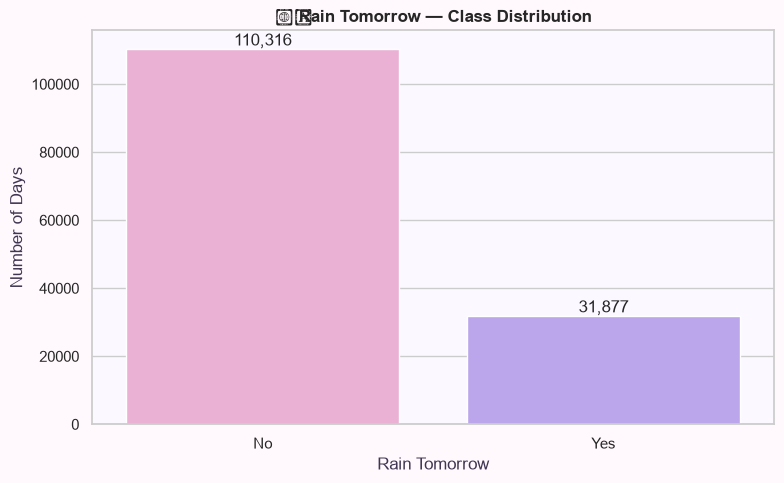

In [9]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="RainTomorrow",
    hue="RainTomorrow",
    palette={"No": PINK, "Yes": PURPLE},
    legend=False
)

plt.title("🌧️ Rain Tomorrow — Class Distribution")
plt.xlabel("Rain Tomorrow")
plt.ylabel("Number of Days")

for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center", va="bottom"
    )

plt.tight_layout()
plt.show()

### Pie chart: Rain vs no rain

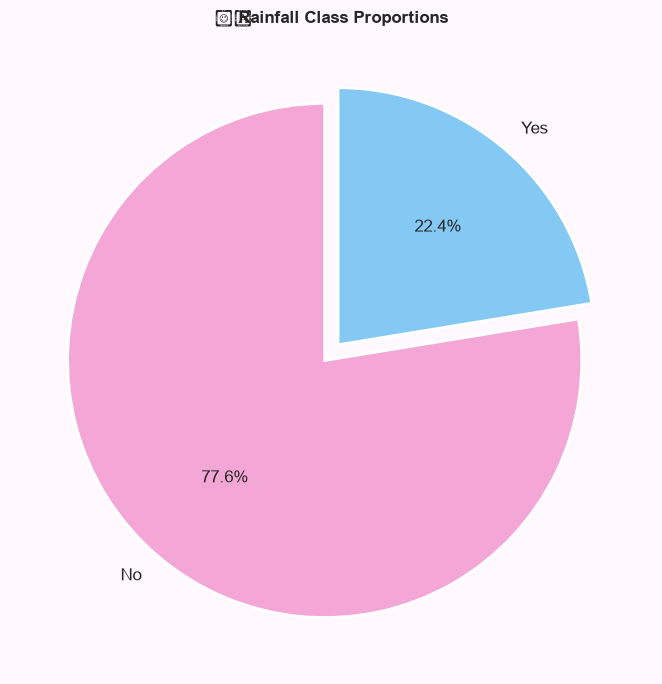

In [10]:
counts = df["RainTomorrow"].value_counts()

plt.figure(figsize=(7, 7))
plt.pie(
    counts,
    labels=counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[PINK, BLUE],
    explode=[0.04, 0.04],
    wedgeprops={"edgecolor": "white", "linewidth": 2},
    textprops={"fontsize": 12}
)

plt.title("☁️ Rainfall Class Proportions")
plt.tight_layout()
plt.show()


### Histogram:Temperature distribution

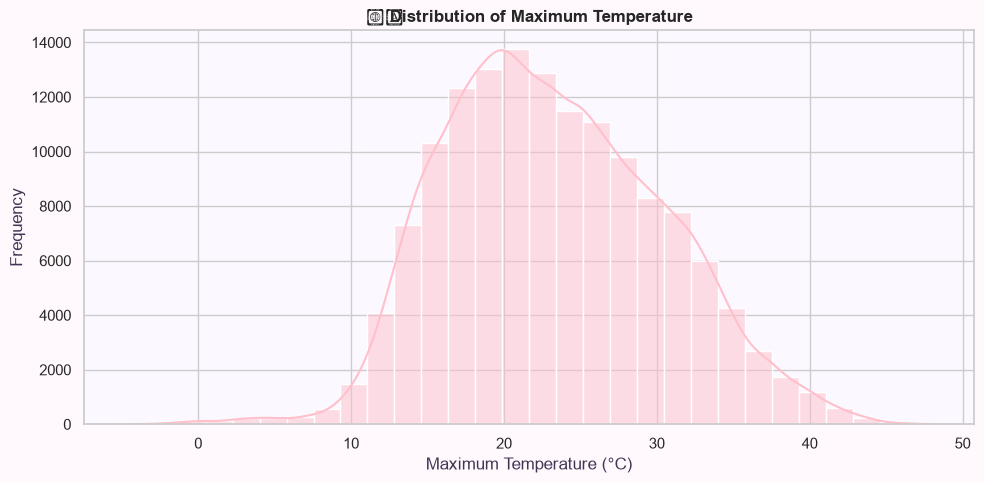

In [11]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="MaxTemp",
    bins=30,
    kde=True,
    color="PINK"
)

plt.title("🌡️ Distribution of Maximum Temperature")
plt.xlabel("Maximum Temperature (°C)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

### Scatter plot: Temperature vs humidity

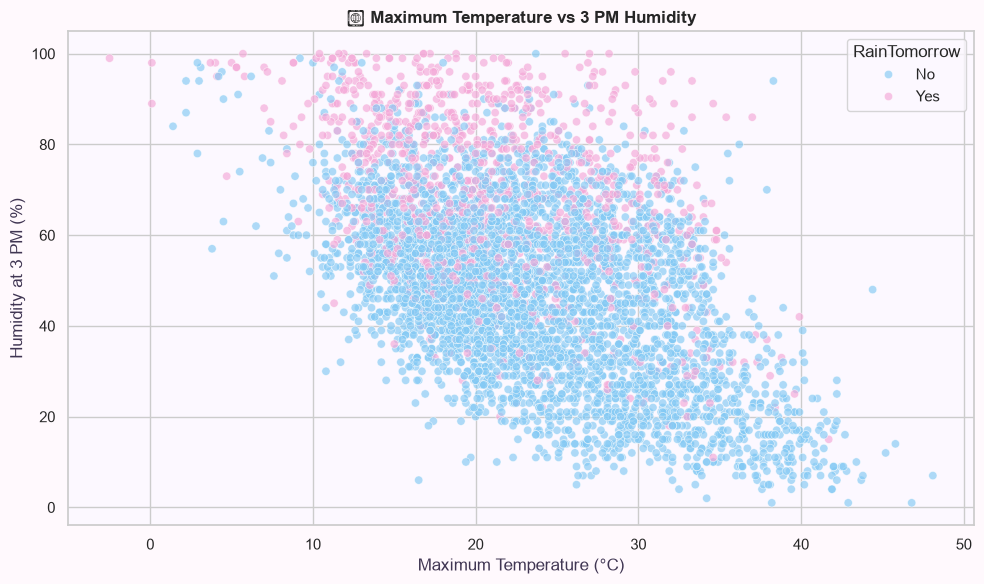

In [12]:
sample = df[["MaxTemp", "Humidity3pm", "RainTomorrow"]].dropna()

# Sample for faster plotting on a large dataset
if len(sample) > 5000:
    sample = sample.sample(5000, random_state=42)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sample,
    x="MaxTemp",
    y="Humidity3pm",
    hue="RainTomorrow",
    palette={"No": BLUE, "Yes": PINK},
    alpha=0.65
)

plt.title("💧 Maximum Temperature vs 3 PM Humidity")
plt.xlabel("Maximum Temperature (°C)")
plt.ylabel("Humidity at 3 PM (%)")
plt.tight_layout()
plt.show()

### Box plot: Humidity by rainfall class

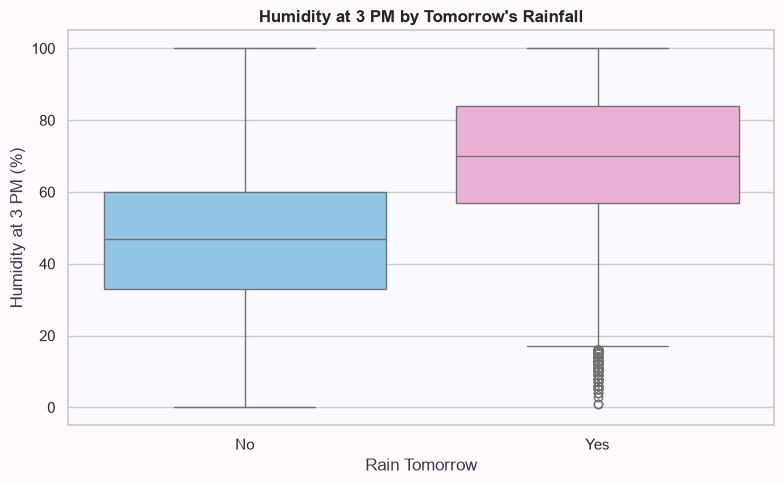

In [13]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="RainTomorrow",
    y="Humidity3pm",
    hue="RainTomorrow",
    palette={"No": BLUE, "Yes": PINK},
    legend=False
)

plt.title("Humidity at 3 PM by Tomorrow's Rainfall")
plt.xlabel("Rain Tomorrow")
plt.ylabel("Humidity at 3 PM (%)")
plt.tight_layout()
plt.show()

### Heatmap: Correlation between numerical features

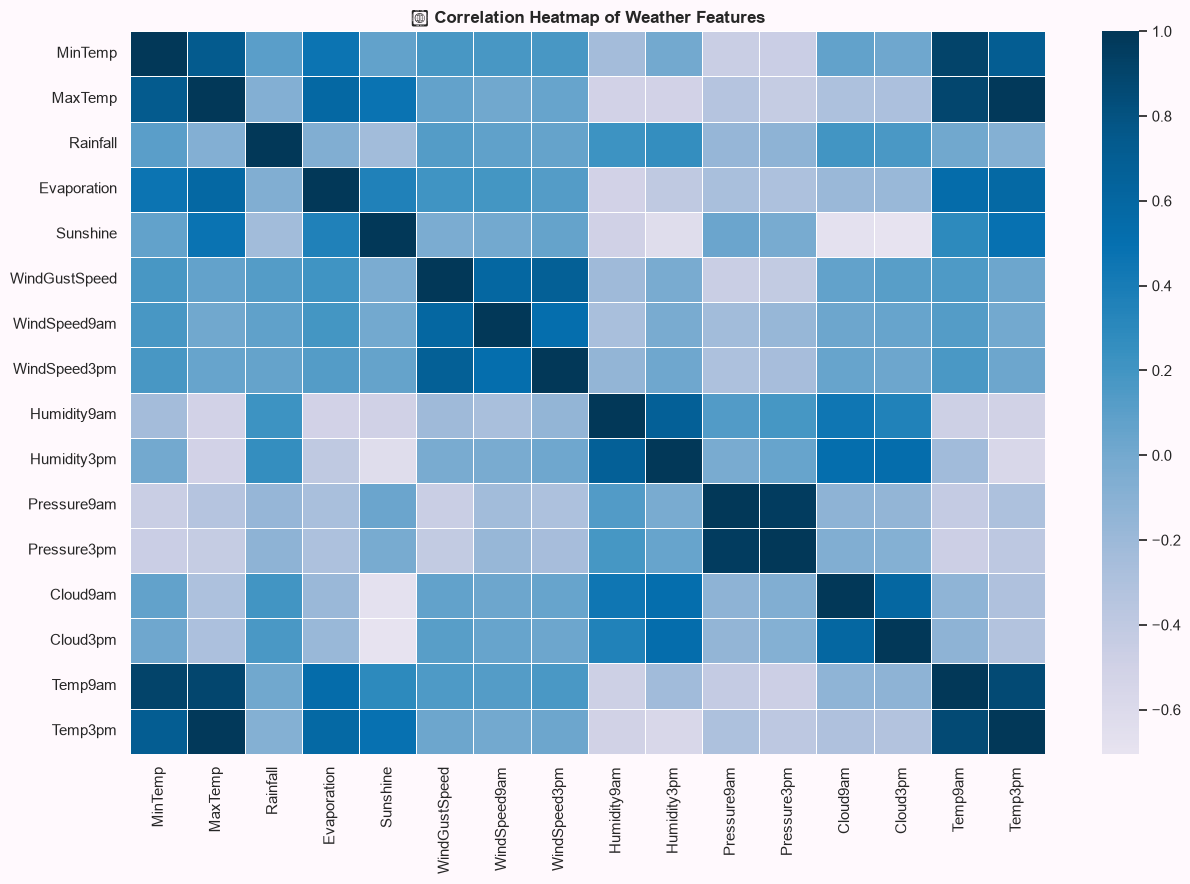

In [14]:
numeric_df = df.select_dtypes(include=np.number)
correlation = numeric_df.corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation,
    cmap="PuBu",
    center=0,
    annot=False,
    linewidths=0.4,
    square=False
)

plt.title("🌈 Correlation Heatmap of Weather Features")
plt.tight_layout()
plt.show()

### Prepare training and testing data

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Training rows: 113754
Testing rows: 28439
Numerical features: 16
Categorical features: 5


### Define the model

In [16]:
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12, random_state=42
    ),
    "SVM": SVC(
        kernel="rbf", probability=True, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "ANN (MLP)": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        max_iter=200,
        early_stopping=True,
        random_state=42
    )
}

print("Models ready for training:")
for name in models:
    print("•", name)

Models ready for training:
• Logistic Regression
• KNN
• Decision Tree
• SVM
• Random Forest
• ANN (MLP)


### Train and evaluate every classifier

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix,
    roc_auc_score
)

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Training Logistic Regression...
Training KNN...


### Linear regression

Dataset loaded successfully!
Dataset shape: (145460, 23)
         Date Location  MinTemp  MaxTemp  Rainfall  Evaporation  Sunshine  \
0  2008-12-01   Albury     13.4     22.9       0.6          NaN       NaN   
1  2008-12-02   Albury      7.4     25.1       0.0          NaN       NaN   
2  2008-12-03   Albury     12.9     25.7       0.0          NaN       NaN   
3  2008-12-04   Albury      9.2     28.0       0.0          NaN       NaN   
4  2008-12-05   Albury     17.5     32.3       1.0          NaN       NaN   

  WindGustDir  WindGustSpeed WindDir9am  ... Humidity9am  Humidity3pm  \
0           W           44.0          W  ...        71.0         22.0   
1         WNW           44.0        NNW  ...        44.0         25.0   
2         WSW           46.0          W  ...        38.0         30.0   
3          NE           24.0         SE  ...        45.0         16.0   
4           W           41.0        ENE  ...        82.0         33.0   

   Pressure9am  Pressure3pm  Cloud9am  Cl

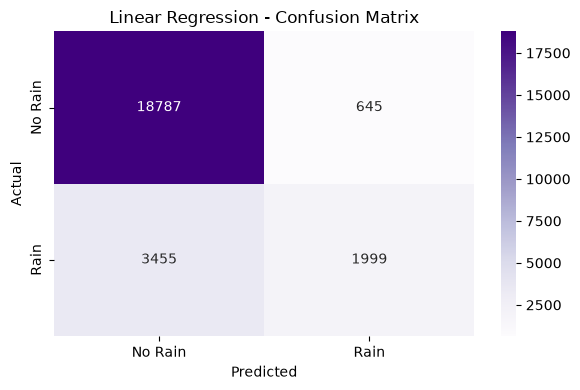

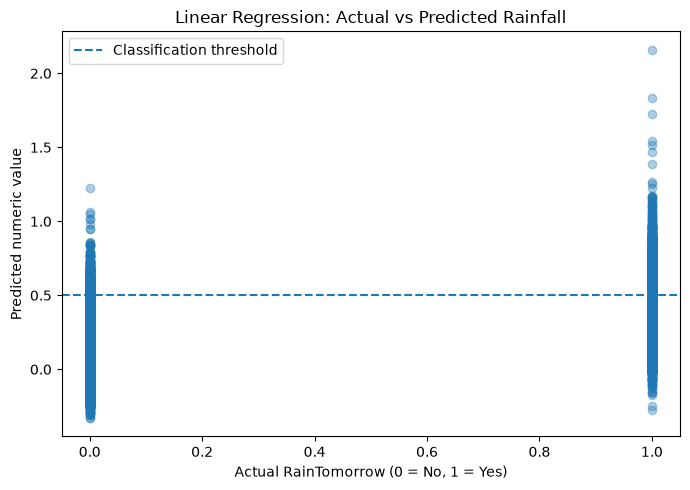


--- SAMPLE PREDICTION ---
Weather conditions:
 MinTemp  MaxTemp  Rainfall  Humidity3pm  Pressure3pm  WindSpeed3pm
    13.2     18.5       2.4         72.0       1000.0          22.0
Predicted numeric value: 0.644
Predicted result: Rain Tomorrow ☔


In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
    confusion_matrix,
    accuracy_score,
    classification_report
)

# Load dataset
df = pd.read_csv("weatherAUS.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

# Select useful features
features = [
    "MinTemp",
    "MaxTemp",
    "Rainfall",
    "Humidity3pm",
    "Pressure3pm",
    "WindSpeed3pm"
]

# Keep required columns and remove missing values
data = df[features + ["RainTomorrow"]].dropna().copy()

# Convert target into numeric values: Yes = 1, No = 0
data["RainTomorrow"] = data["RainTomorrow"].map({
    "No": 0,
    "Yes": 1
})

data = data.dropna()

X = data[features]
y = data["RainTomorrow"]

print("\nCleaned dataset shape:", data.shape)

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Train Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Convert predictions into Yes/No using threshold 0.5
y_pred_class = (y_pred >= 0.5).astype(int)

# Evaluation metrics
print("\n--- LINEAR REGRESSION RESULTS ---")
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))
print("MSE:", round(mean_squared_error(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 4))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

print("\n--- RAINFALL CLASSIFICATION RESULTS ---")
print("Accuracy:", round(accuracy_score(y_test, y_pred_class) * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_class,
    labels=[0, 1],
    target_names=["No Rain", "Rain"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred_class, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["No Rain", "Rain"],
    yticklabels=["No Rain", "Rain"]
)
plt.title("Linear Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Actual vs predicted plot
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.35)
plt.axhline(0.5, linestyle="--", label="Classification threshold")
plt.xlabel("Actual RainTomorrow (0 = No, 1 = Yes)")
plt.ylabel("Predicted numeric value")
plt.title("Linear Regression: Actual vs Predicted Rainfall")
plt.legend()
plt.tight_layout()
plt.show()

# Predict for a sample weather observation
sample = X_test.iloc[[0]]
prediction = model.predict(sample)[0]

print("\n--- SAMPLE PREDICTION ---")
print("Weather conditions:")
print(sample.to_string(index=False))
print("Predicted numeric value:", round(prediction, 3))
print("Predicted result:", "Rain Tomorrow ☔" if prediction >= 0.5
      else "No Rain Tomorrow ☀️")

### ROC curve and AUC

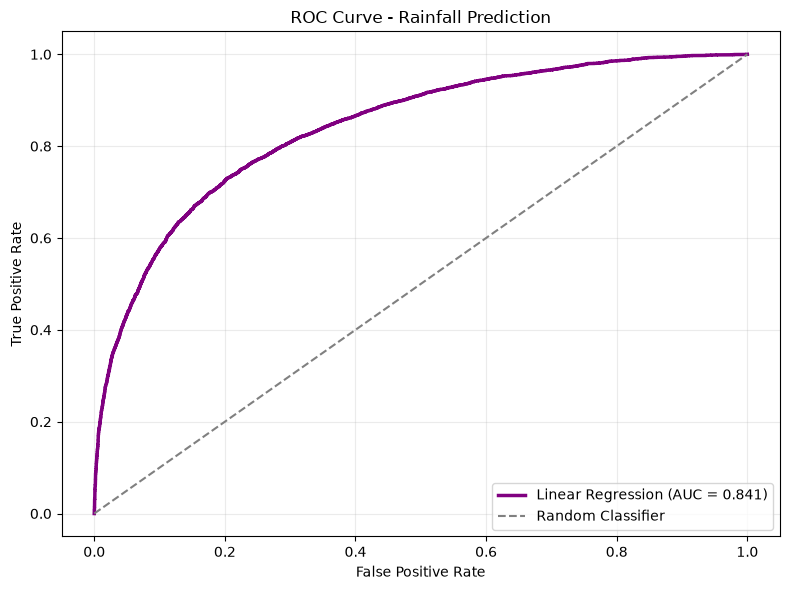

ROC-AUC Score: 0.8415


In [2]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Check that the required variables exist
if "y_test" not in globals() or "y_pred" not in globals():
    raise NameError(
        "Run your Linear Regression training cell first to create y_test and y_pred."
    )

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr, tpr,
    color="purple",
    linewidth=2.5,
    label=f"Linear Regression (AUC = {roc_auc:.3f})"
)

# Random classifier reference line
plt.plot(
    [0, 1], [0, 1],
    color="gray",
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Rainfall Prediction")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"ROC-AUC Score: {roc_auc:.4f}")

### Decision tree

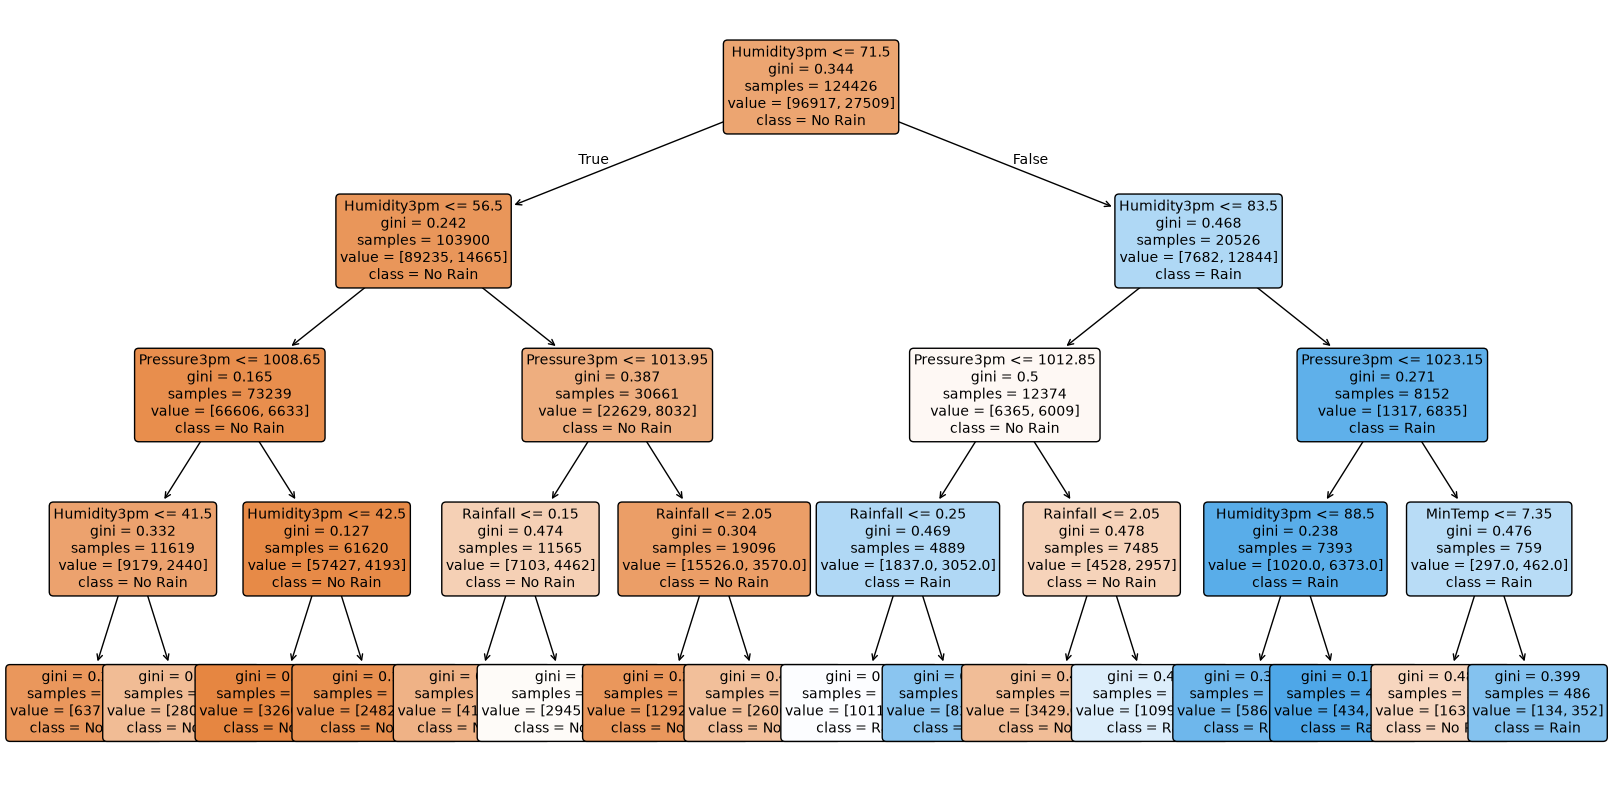

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Load dataset
df = pd.read_csv("weatherAUS.csv")

# Select features and target
features = [
    "MinTemp", "MaxTemp", "Rainfall",
    "Humidity3pm", "Pressure3pm", "WindSpeed3pm"
]

data = df[features + ["RainTomorrow"]].dropna()

X = data[features]
y = data["RainTomorrow"].map({"No": 0, "Yes": 1})

# Train Decision Tree
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X, y)
plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=features,
    class_names=["No Rain", "Rain"],
    filled=True,
    rounded=True,
    fontsize=10
)

plt.show()

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# Load dataset
df = pd.read_csv("weatherAUS.csv")

# Select features
features = ["MinTemp", "MaxTemp", "Rainfall",
            "Humidity3pm", "Pressure3pm", "WindSpeed3pm"]

data = df[features + ["RainTomorrow"]].dropna()

X = data[features]
y = data["RainTomorrow"].map({"No": 0, "Yes": 1})

# Split and train model
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train, y_train)

# Check model performance
predictions = model.predict(X_test)
print("Model Accuracy:", round(accuracy_score(y_test, predictions) * 100, 2), "%")

# Predict for one weather record
sample = X_test.iloc[[0]]
result = model.predict(sample)[0]

print("\nWeather Conditions:")
print(sample.to_string(index=False))
print("\nRain Tomorrow:", "Yes ☔" if result == 1 else "No ☀️")

Model Accuracy: 84.27 %

Weather Conditions:
 MinTemp  MaxTemp  Rainfall  Humidity3pm  Pressure3pm  WindSpeed3pm
     4.6     17.0       1.6         43.0       1020.3          28.0

Rain Tomorrow: No ☀️


In [ ]:

print("🌦️ RAINFALL PREDICTION SYSTEM 🌦️")
print("Enter weather details for your chosen observation time:\n")

min_temp = float(input("Minimum Temperature (°C): "))
max_temp = float(input("Maximum Temperature (°C): "))
rainfall = float(input("Rainfall (mm): "))
humidity = float(input("Humidity (%) at your chosen time: "))
pressure = float(input("Air Pressure (hPa) at your chosen time: "))
wind_speed = float(input("Wind Speed (km/h) at your chosen time: "))

user_data = pd.DataFrame(
    [[min_temp, max_temp, rainfall, humidity, pressure, wind_speed]],
    columns=features
)

prediction = model.predict(user_data)[0]
probability = model.predict_proba(user_data)[0][1]

print("\n========== PREDICTION RESULT ==========")

if prediction == 1:
    print("☔ It is predicted to RAIN TOMORROW!")
else:
    print("☀️ It is predicted NOT TO RAIN TOMORROW!")

print(f"Model-estimated rain score: {probability * 100:.2f}%")
print("=======================================")


🌦️ RAINFALL PREDICTION SYSTEM 🌦️
Enter weather details for your chosen observation time:

